# Кодирование и масштабирование

**Цель**: провести кодирование и масштабирование имеющихся данных с помощью средств языка программирования Python

**Выполнил:** ст.группы 24ВВИ1 Будников А.С.

## Теоретическая часть

### 1. Почему этап кодирования и масштабирования данных является обязательным перед применением алгоритмов машинного обучения?

Алгоритмы машинного обучения по своей сути представяют набор последовательных арифметических операций. Алгоритм не работает со строками, поэтому необходимо превратить строковые значения в числовые литералы. Здесь также важно упомянуть, что кодировать нужно с учетом осбенностей данных, так как при неправильном кодировании модель может восмпринимать категории, как дискретные числовые значения и оперировать с ними как с числами, что приведет к неверной интерпретации. Разный масштаб числовых признаков в свою очередь может привести к игнорированию признаков с относительно малыми значениями и диапазонами, что также приведет к ошибкам при обучении. Не забыть про некотрые методы, которые работают с расстояниями, так что отсутствие масштабирования может исказить результат их работы. Таким образом, кодирование и масштабирование помогают привести признаки к надлежащему для обучения виду.

### 2. В чём различие между: числовыми признаками; категориальными признаками с точки зрения их подготовки к анализу?

С точки зрения подготовки к анализу числовые признаки уже представлены в виде чисел, поэтому в кодировании они не нуждаются, требуя только масштабирование. Категориальные, отлично от числовых, имеют конечное значение дискретных, или строковых значений, поэтому для работы с маоделями машинного обучения требуется провести кодирование этих признаков, то есть привести к числовому виду. При этом способ кодирования зависит от природы самих категориальных данных: для неупорядочнных OneHot, для порядковах другие методы.

### 3. В чём принципиальная разница между: LаbelEncoder; OneHotEncoder? В каких случаях каждый из них используется?

LabelEncoder заменяет каждую категорию в наборе данных числовым значением, которые будет соотносится с данныой категорией. Может использоваться как для кодирования целевой переменной, так и для кодирования упорядоченных признаков. OneHotEncoder создает по одному  бинарному столбцу на каждую категорию признака, создавая ряд флагов принадлежность к категории. Может применяться для неупорядоченных признаков.

### 4. Почему большинство алгоритмов машинного обучения чувствительны к масштабу признаков?

Большинство модельей для своей работы используют расстояние между разделяющей плоскостью и объектами разделяемых классов. Поэтому разный масштаб признаков может привести к тому, что вклад более крупного признака будет больше вклада признака с меньшим масштабом. Для регрессионного анализа единый масштаб позволяет сравнивать регрессионные коэффициенты между собой при признаках и корректно применять регуляризацию.

### 5. В чём различие между: StandardScaler; MinMaxScaler? Как масштабирование влияет на распределение данных?

Оба метода реализуют линейные преобразования данных, поэтому на форму распределения они не влияют; меняются только статистические показатели такие как, среднее, экстремумы и стандартное отклонение.

StandardScaler преобразует данные к виду, при котором стандартное отклонение примерно равно одному, а среднее нулю. Диапазон при 
этом не ограничивается, центр не сжимается. MinMaxScaler напротив подгоняет диапазон к промежутку от 0 до 1, хотя форма гистограммы визуально не меняется, данные все равно начинают сильно сжиматься в центре, засчет того, что хвосты начинают занимать львиную долю выделенного диапазона.

Выбор метода полностью зависит от целей масштабирования. Стандартизация является более универсальным подходам, так как обеспечивает сопоставимый масштаб и не сильно искажает некотоыре показатели. Мотивация к использованию MinMaxScaler включает устойчивость к очень небольшим стандартным отклонениям функций и сохранение нулевых записей в разреженных данных.

## Практическая часть

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data/covtype-5.csv') # default delimiter is ','

In [3]:
renamed_cols = {
    'Elevation': 'Высота_над_уровнем_моря',
    'Aspect': 'Азимут_склона',
    'Slope': 'Уклон_склона',
    'Horizontal_Distance_To_Hydrology': 'Расстояние_до_воды_гориз',
    'Vertical_Distance_To_Hydrology': 'Расстояние_до_воды_верт',
    'Horizontal_Distance_To_Roadways': 'Расстояние_до_дорог',
    'Hillshade_9am': 'Освещённость_9_утра',
    'Hillshade_Noon': 'Освещённость_полдень',
    'Hillshade_3pm': 'Освещённость_3_дня',
    'Horizontal_Distance_To_Fire_Points': 'Расстояние_до_пожарных_точек',
    'Cover_Type': 'Тип_лесного_покрова',
}
for i in range(1, 5):
    renamed_cols[f'Wilderness_Area{i}'] = f'Зона_дикой_природы_{i}'

for i in range(1, 41):
    renamed_cols[f'Soil_Type{i}'] = f'Тип_почвы_{i}'

df = df.rename(columns=renamed_cols)

In [4]:
df.head()

,Высота_над_уровнем_моря,Азимут_склона,Уклон_склона,Расстояние_до_воды_гориз,Расстояние_до_воды_верт,Расстояние_до_дорог,Освещённость_9_утра,Освещённость_полдень,Освещённость_3_дня,Расстояние_до_пожарных_точек,...,Тип_почвы_32,Тип_почвы_33,Тип_почвы_34,Тип_почвы_35,Тип_почвы_36,Тип_почвы_37,Тип_почвы_38,Тип_почвы_39,Тип_почвы_40,Тип_лесного_покрова
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [5]:
print(f"Rows={df.shape[0]}", f"Columns={df.shape[1]}", sep='\t')

Rows=580966	Columns=55


## Анализ

В качестве датасета используется [Forest Cover Types](https://www.kaggle.com/datasets/uciml/forest-cover-type-dataset/data).
Здесь содержатся данные о типах лесного покрова для территорий национального парка Рузвельта в Колорадо США. Каждая строка таблицы описывает один участок земли площадью 30×30 метров. Набор признаков включает информацию о типе дерева, степени затенения, расстоянии до близлежащих ориентиров (дорог и т. д.), типе почвы и местном рельефе. 

Всего в датасете 581 012 записей и 55 столбцов, однако после очистки количество строк сократилось до 580 966. Для удобства чтения столбцы были переименованы.

Расшифрока значений целевой переменной:

0. Ель/Пихра
1. Сосна скрученная
2. Сосна пондероза
3. Тополь/Ива
4. Осина
5. Дугласова пихта
6. Круммхольц

In [6]:
print(df.dtypes)

Высота_над_уровнем_моря         int64
Азимут_склона                   int64
Уклон_склона                    int64
Расстояние_до_воды_гориз        int64
Расстояние_до_воды_верт         int64
Расстояние_до_дорог             int64
Освещённость_9_утра             int64
Освещённость_полдень            int64
Освещённость_3_дня              int64
Расстояние_до_пожарных_точек    int64
Зона_дикой_природы_1            int64
Зона_дикой_природы_2            int64
Зона_дикой_природы_3            int64
Зона_дикой_природы_4            int64
Тип_почвы_1                     int64
Тип_почвы_2                     int64
Тип_почвы_3                     int64
Тип_почвы_4                     int64
Тип_почвы_5                     int64
Тип_почвы_6                     int64
Тип_почвы_7                     int64
Тип_почвы_8                     int64
Тип_почвы_9                     int64
Тип_почвы_10                    int64
Тип_почвы_11                    int64
Тип_почвы_12                    int64
Тип_почвы_13

In [7]:
print(df.nunique())
categorical_cols = [col for col in df.columns if df[col].nunique() == 2]
numeric_cols = [col for col in df.columns if df[col].nunique() > 2 and col != 'Тип_лесного_покрова']
print(f'\nкатегориальные={categorical_cols}')
print(f'\nчисловые={numeric_cols}')

Высота_над_уровнем_моря         1978
Азимут_склона                    361
Уклон_склона                      56
Расстояние_до_воды_гориз         551
Расстояние_до_воды_верт          700
Расстояние_до_дорог             5785
Освещённость_9_утра              203
Освещённость_полдень             172
Освещённость_3_дня               255
Расстояние_до_пожарных_точек    5827
Зона_дикой_природы_1               2
Зона_дикой_природы_2               2
Зона_дикой_природы_3               2
Зона_дикой_природы_4               2
Тип_почвы_1                        2
Тип_почвы_2                        2
Тип_почвы_3                        2
Тип_почвы_4                        2
Тип_почвы_5                        2
Тип_почвы_6                        2
Тип_почвы_7                        2
Тип_почвы_8                        2
Тип_почвы_9                        2
Тип_почвы_10                       2
Тип_почвы_11                       2
Тип_почвы_12                       2
Тип_почвы_13                       2
Т

## Анализ

Как видно из двух верхних пунктов таблица содержит данные типа ``int64``, поэтому выделить категориальные признаки здесь представляется возможным только путём отсечения столбцов по количеству уникальных значений. В данном случае пороговым числом было выбрано **2**. В данном датасете эвристика работает хорошо, потому что все категориальные признаки являются бинарными, и разрыв между группами очень велик.

Такой подход во многом оправдан: признаки с малым числом уникальных значений с высокой вероятностью являются бинарными или порядковыми категориями, тогда как признаки с большим числом уникальных значений - это непрерывные числовые величины. Важно также исключить из списка целевую переменную Cover_Type, имеющую 7 уникальных значений.

В результате разделения были получены две группы:

  - Числовые признаки (10 столбцов): Elevation, Aspect, Slope, Horizontal_Distance_To_Hydrology, Vertical_Distance_To_Hydrology, Horizontal_Distance_To_Roadways, Hillshade_9am, Hillshade_Noon, Hillshade_3pm, Horizontal_Distance_To_Fire_Points
  - Категоральные признаки (45 столбцов): Wilderness_Area1 - Wilderness_Area4 (бинарные), Soil_Type1 - Soil_Type40 (бинарные)


В рассматриваемом датасете категориальными являются 44 бинарных признака, а также целевая переменная. К бинарным примененения кодирования не требуется, так как из-за особенностей оборудования, или подготовки датасета его создателями, эти признаки уже напоминают результат One-Hot Encoding. Целевая переменная `Тип_лесного_покрова` - номинальная, имеет 7 классов. С одной стороны, метки классов уже закодированы значениями от 1 до 7, но лучше привести их к каноничному виду от 0 до 6.

In [8]:
X = df.drop(columns=['Тип_лесного_покрова'])
y = df['Тип_лесного_покрова']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

print(f"Train: {X_train.shape[0]}")
print(f"Test : {X_test.shape[0]}")
print(f'Доли классов в тестовой {y_test.value_counts(normalize=True)}')
print(f'Доли классов в тренировочной {y_train.value_counts(normalize=True)}')

Train: 464772
Test : 116194
Доли классов в тестовой Тип_лесного_покрова
2    0.487573
1    0.364623
3    0.061544
7    0.035303
6    0.029890
5    0.016343
4    0.004725
Name: proportion, dtype: float64
Доли классов в тренировочной Тип_лесного_покрова
2    0.487577
1    0.364626
3    0.061540
7    0.035303
6    0.029886
5    0.016339
4    0.004729
Name: proportion, dtype: float64


## Анализ

Перед масштабированием выборка была разделена на тренировочную и тестовую части. Использован `train_test_split` с параметрами из лекции: `test_size=0.2`, `stratify=y` и `random_state=42`. Тренировочная получила 80% строк (464 772), а тестовая - 20% (116 194). Стратификация сохранила доли всех семи классов в обеих частях, расхождения начинаются только после 5 знака после запятой.

In [9]:
scaler = StandardScaler()
scaler.fit(X_train[numeric_cols])

X_trs = X_train.copy()
X_tss = X_test.copy()

X_trs[numeric_cols] = scaler.transform(X_train[numeric_cols])
X_tss[numeric_cols]  = scaler.transform(X_test[numeric_cols])

print('Train после:', X_trs[numeric_cols].agg(['mean', 'std']).T, sep='\n')
print()
print('Test после:', X_tss[numeric_cols].agg(['mean', 'std']).T, sep='\n')

dfs = pd.concat([X_trs, X_tss])
dfs['Тип_лесного_покрова'] = pd.concat([y_train, y_test])

print()
for c in numeric_cols:
    tr_min, tr_max = X_trs[c].min(), X_trs[c].max()
    te_min, te_max = X_tss[c].min(),  X_tss[c].max()
    print(f"{c:<35}[{tr_min:.3f}; {tr_max:.3f}]".ljust(22) + f"[{te_min:.3f}; {te_max:.3f}]")

print(f"\nРазмерность после масштабирования: {dfs.shape}")

Train после:
                                      mean       std
Высота_над_уровнем_моря      -7.080172e-16  1.000001
Азимут_склона                -5.833895e-17  1.000001
Уклон_склона                 -8.659115e-17  1.000001
Расстояние_до_воды_гориз     -1.164333e-16  1.000001
Расстояние_до_воды_верт      -3.234938e-17  1.000001
Расстояние_до_дорог           3.424509e-17  1.000001
Освещённость_9_утра          -8.072056e-17  1.000001
Освещённость_полдень         -5.970875e-16  1.000001
Освещённость_3_дня            2.530467e-16  1.000001
Расстояние_до_пожарных_точек -1.651102e-17  1.000001

Test после:
                                  mean       std
Высота_над_уровнем_моря      -0.002539  0.999027
Азимут_склона                -0.006684  0.997279
Уклон_склона                  0.001297  1.001488
Расстояние_до_воды_гориз      0.003138  1.003524
Расстояние_до_воды_верт       0.003882  1.002597
Расстояние_до_дорог          -0.005938  0.998608
Освещённость_9_утра           0.004943  0.997530

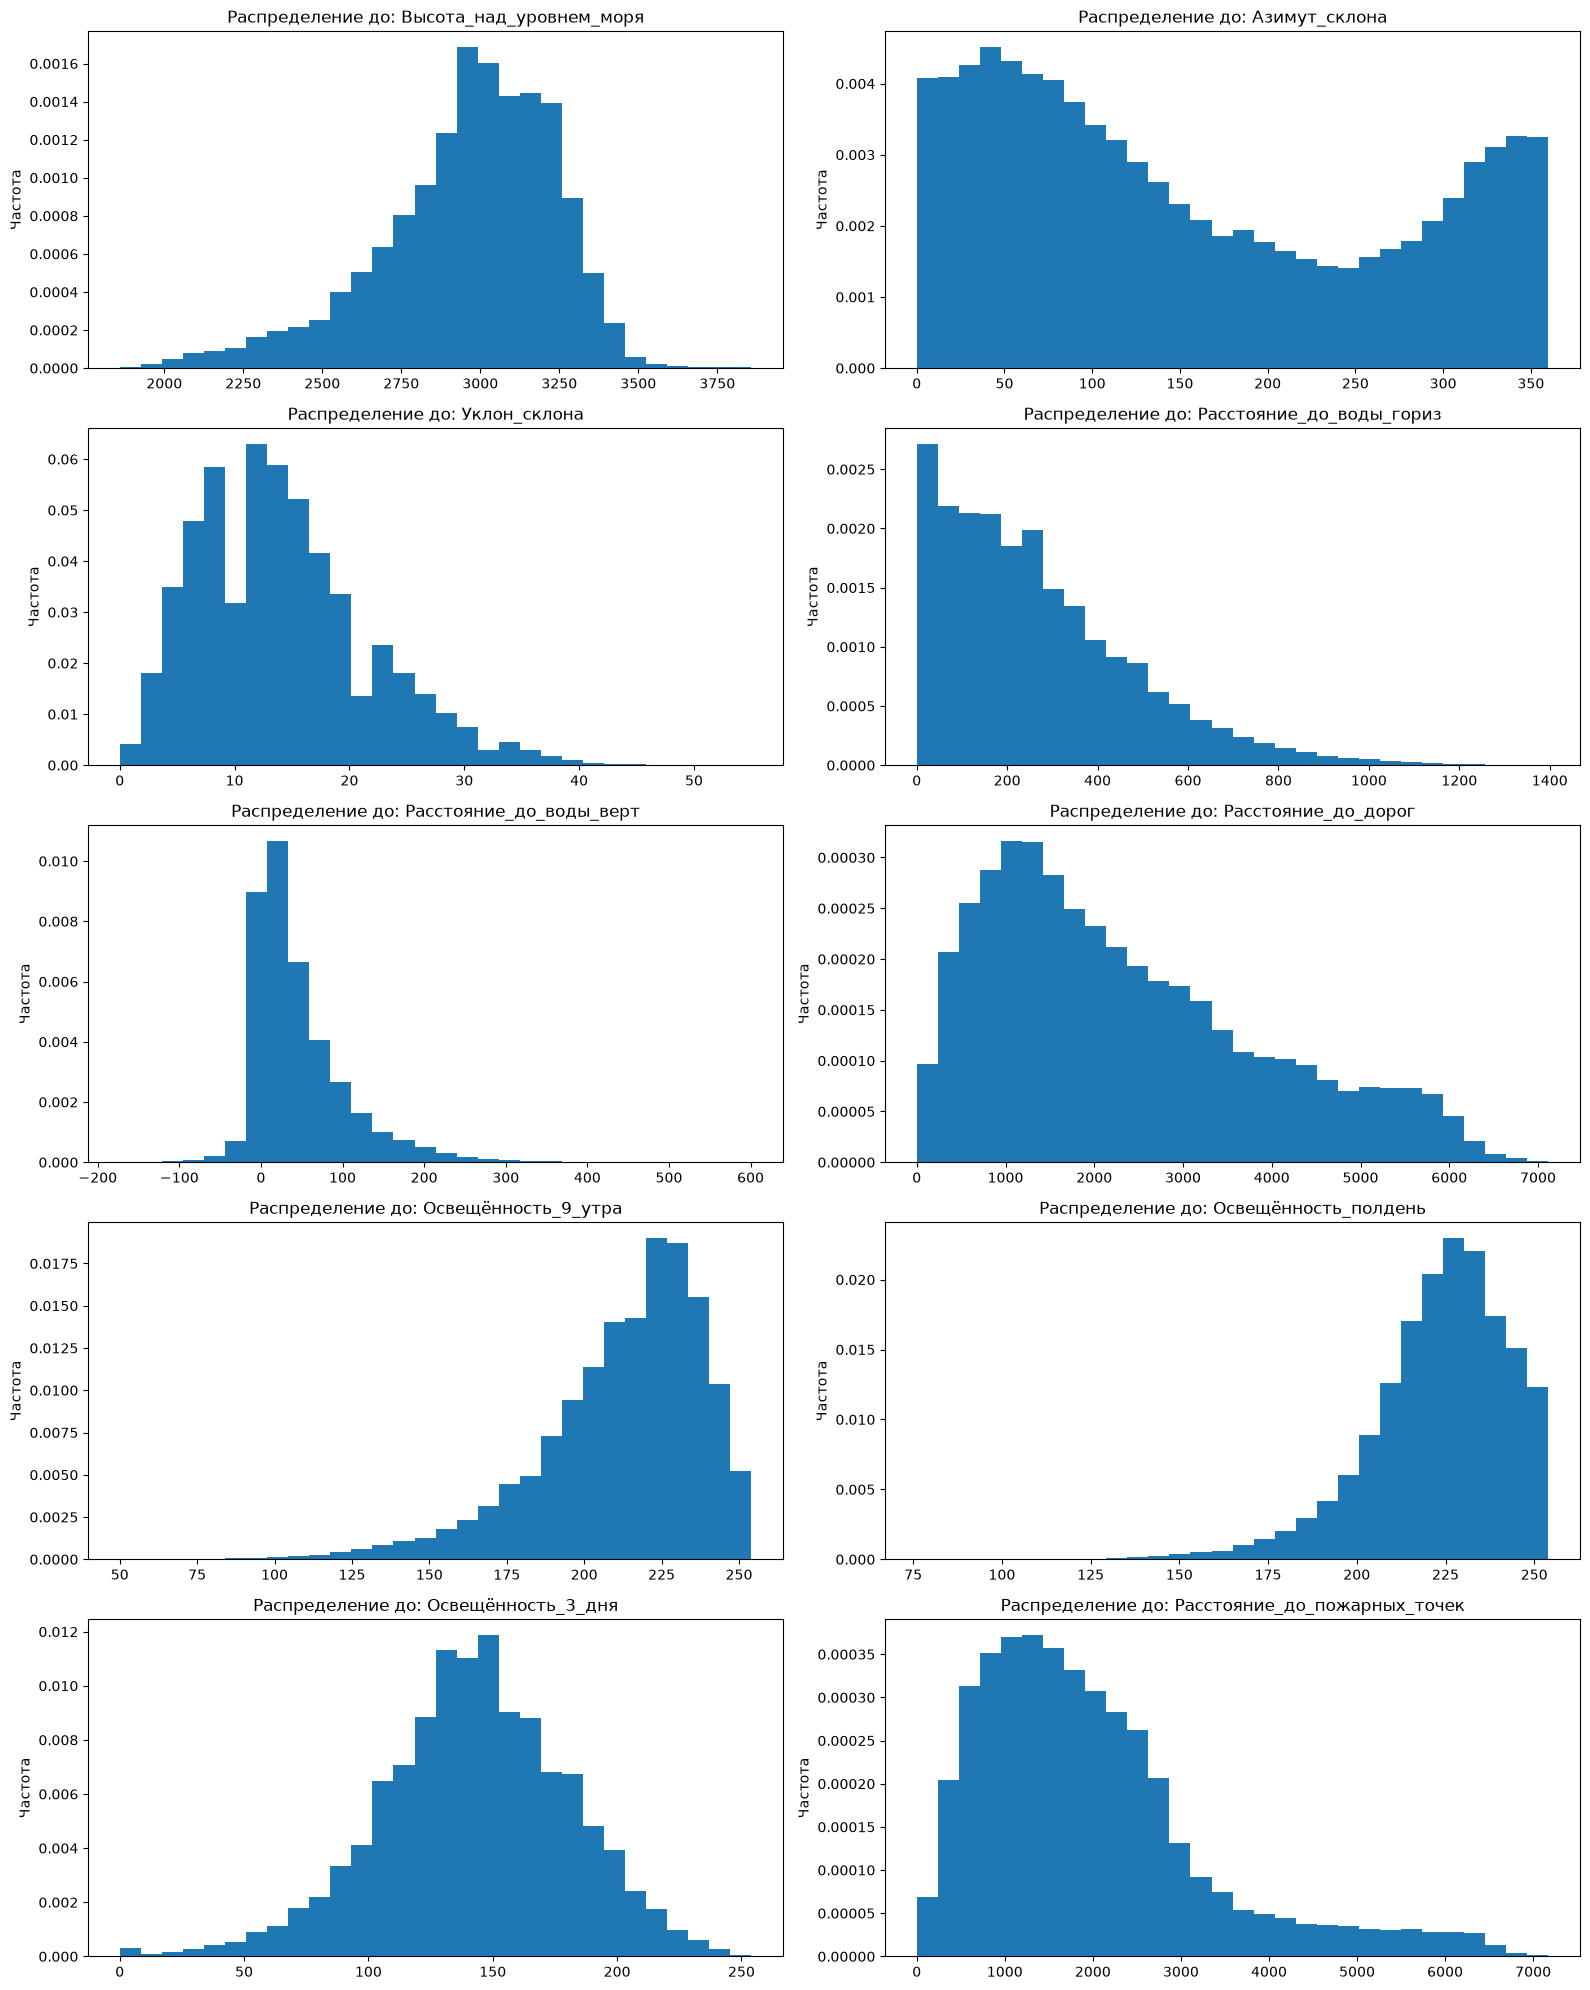

In [10]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=30, density=True)
    axes[i].set_title(f"Распределение до: {col}", fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Частота")

plt.tight_layout()
plt.show()

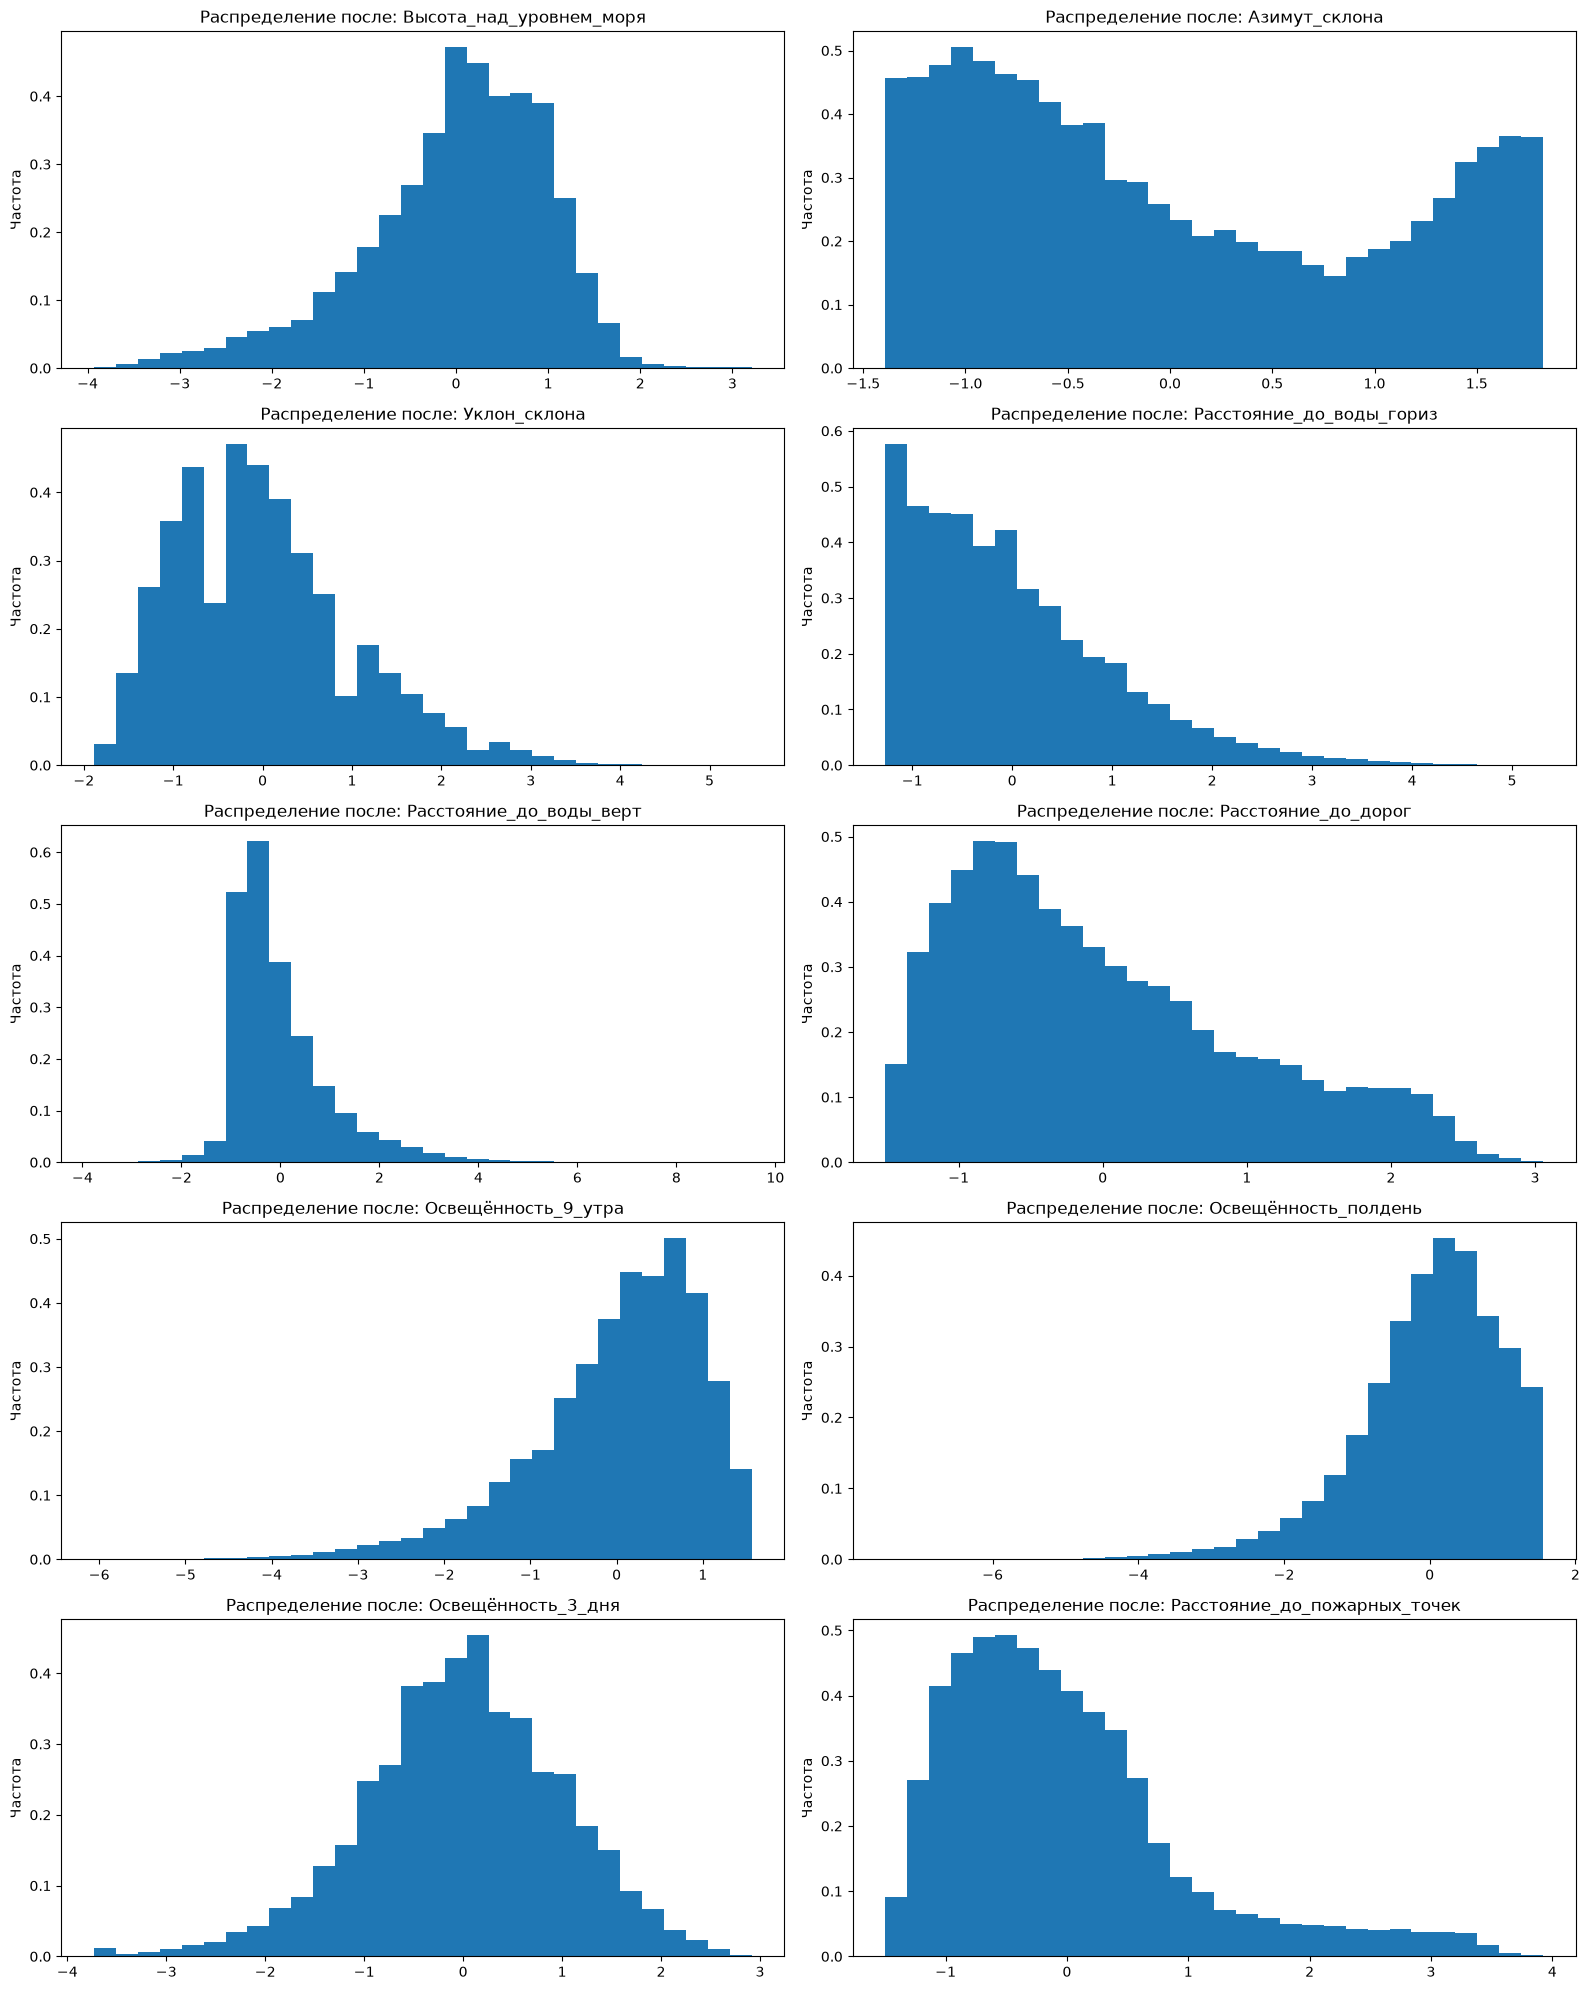

In [11]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(dfs[col], bins=30, density=True)
    axes[i].set_title(f"Распределение после: {col}", fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Частота")

plt.tight_layout()
plt.show()

## Анализ

Числовые переменные были масштабированы с использованием __StandardScaler__, то есть стандартизации. Параметры вычислялись только на тренировочной выборке, а затем применялись к обеим частям `через transform`, что исключает утечку данных из теста.
    
Как видно из вывода, диапазоны значений изменились довольно сильно. Так, если признак `Высота_над_уровнем_моря` изначально имел диапазон `(1859; 3858)`, то после стандартизации диапазон его значений сузился до `(-3.93; 3.21)`. Такая ситуация наблюдается со всеми переменными, за исключением того, что из-за сохранения методом масштабирования исходного распределения, как на графике, так и в числах, хорошо видны хвосты, оставшиеся от старых значений. Стоит также отметить, что после масштабирования степень различия между значениями сильно снизилась. Допустим, если до этого `Расстояние_до_пожарных_точек` имело самый широкий диапазон значений, то после применения стандартизации, его значения были приведены к соразмерным остальным данным.

Гистограммы распределения визуально не отличаются, что подтвержает тезис о том, что распредление не пострадало.

Теперь, в перспективе, после отбора данных, к набору данных можно будет применить любой метод машинного обучения, как чувствуительный к масштабу признаков, как регрессия, так и не чувствительные, например, деревья решений, которые работают с пороговыми значениями.

Для задания 2.2.1-2.2.3 упомяну, что в выбранном для анализа наборе данных кодирование категориальных признаков не требуется, так как, повторюсь, они изначально закодированы по принципу OneHot и восстанавливать их в единую переменную особого смысла не имеет. Однако, здесь же, отвечу, что __OneHot__ предпочтительнее для неупорядоченных переменных, которые нельзя различить неравенствами и не имеющим порядка. Так, нельзя сказать, что `Тип_почвы_21` больше чем `Тип_почвы_24` - это не имеет смысла. OneHot устраняет эту проблему, приводя каждую категорию к независимому индикатору.

In [12]:
mmscaler = MinMaxScaler()
mmscaler.fit(X_train[numeric_cols])  

X_trm = X_train.copy()
X_tsm = X_test.copy()

X_trm[numeric_cols] = mmscaler.transform(X_train[numeric_cols])
X_tsm[numeric_cols]  = mmscaler.transform(X_test[numeric_cols])

print('Train после:', X_trm[numeric_cols].agg(['mean', 'std']).T, sep='\n')
print()
print('Test после:', X_tsm[numeric_cols].agg(['mean', 'std']).T, sep='\n')

dfmm = pd.concat([X_trm, X_tsm])
dfmm['Тип_лесного_покрова'] = pd.concat([y_train, y_test])

print()
for c in numeric_cols:
    tr_min, tr_max = X_trm[c].min(), X_trm[c].max()
    te_min, te_max = X_tsm[c].min(),  X_tsm[c].max()
    print(f"{c:<35}[{tr_min:.3f}; {tr_max:.3f}]".ljust(22) + f"[{te_min:.3f}; {te_max:.3f}]")

print(f"\nРазмерность после масштабирования: {dfmm.shape}")

Train после:
                                  mean       std
Высота_над_уровнем_моря       0.550307  0.140159
Азимут_склона                 0.432790  0.311040
Уклон_склона                  0.256338  0.135951
Расстояние_до_воды_гориз      0.192774  0.152043
Расстояние_до_воды_верт       0.284162  0.075473
Расстояние_до_дорог           0.330475  0.219155
Освещённость_9_утра           0.794745  0.131160
Освещённость_полдень          0.827736  0.110789
Освещённость_3_дня            0.561337  0.150500
Расстояние_до_пожарных_точек  0.276073  0.184577

Test после:
                                  mean       std
Высота_над_уровнем_моря       0.549951  0.140023
Азимут_склона                 0.430711  0.310194
Уклон_склона                  0.256515  0.136153
Расстояние_до_воды_гориз      0.193251  0.152578
Расстояние_до_воды_верт       0.284455  0.075669
Расстояние_до_дорог           0.329174  0.218850
Освещённость_9_утра           0.795393  0.130835
Освещённость_полдень          0.827442  0.1

In [13]:
df[numeric_cols].describe()

,Высота_над_уровнем_моря,Азимут_склона,Уклон_склона,Расстояние_до_воды_гориз,Расстояние_до_воды_верт,Расстояние_до_дорог,Освещённость_9_утра,Освещённость_полдень,Освещённость_3_дня,Расстояние_до_пожарных_точек
count,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000
mean,2959.371492,155.654639,14.100545,269.438535,46.418050,2350.141607,212.154408,223.326498,142.531439,1980.269727
std,279.983524,111.913924,7.479512,212.553451,58.295577,1559.295923,26.743362,19.739619,38.264497,1324.116452
min,1859.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,50.000000,76.000000,0.000000,0.000000
25%,2809.000000,58.000000,9.000000,108.000000,7.000000,1106.000000,198.000000,213.000000,119.000000,1024.000000
50%,2996.000000,127.000000,13.000000,218.000000,30.000000,1997.000000,218.000000,226.000000,143.000000,1710.000000
75%,3163.000000,260.000000,18.000000,384.000000,69.000000,3328.000000,231.000000,237.000000,168.000000,2550.000000
max,3858.000000,360.000000,55.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000


In [14]:
dfmm[numeric_cols].describe()

,Высота_над_уровнем_моря,Азимут_склона,Уклон_склона,Расстояние_до_воды_гориз,Расстояние_до_воды_верт,Расстояние_до_дорог,Освещённость_9_утра,Освещённость_полдень,Освещённость_3_дня,Расстояние_до_пожарных_точек
count,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000
mean,0.550236,0.432374,0.256374,0.192869,0.284220,0.330215,0.794875,0.827677,0.561147,0.276111
std,0.140132,0.310872,0.135991,0.152150,0.075512,0.219095,0.131095,0.110897,0.150648,0.184623
min,-0.000501,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.474975,0.161111,0.163636,0.077309,0.233161,0.155403,0.725490,0.769663,0.468504,0.142777
50%,0.568569,0.352778,0.236364,0.156049,0.262953,0.280596,0.823529,0.842697,0.562992,0.238427
75%,0.652152,0.722222,0.327273,0.274875,0.313472,0.467613,0.887255,0.904494,0.661417,0.355549
max,1.000000,1.000000,1.000000,1.000000,1.002591,1.000000,1.000000,1.000000,1.000000,1.000139


In [15]:
dfs[numeric_cols].describe()

,Высота_над_уровнем_моря,Азимут_склона,Уклон_склона,Расстояние_до_воды_гориз,Расстояние_до_воды_верт,Расстояние_до_дорог,Освещённость_9_утра,Освещённость_полдень,Освещённость_3_дня,Расстояние_до_пожарных_точек
count,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000,580966.000000
mean,-0.000508,-0.001337,0.000259,0.000628,0.000776,-0.001188,0.000989,-0.000530,-0.001259,0.000206
std,0.999806,0.999460,1.000298,1.000707,1.000521,0.999725,0.999508,1.000975,1.000983,1.000252
min,-3.929875,-1.391428,-1.885525,-1.267895,-3.765073,-1.507954,-6.059383,-7.471298,-3.729821,-1.495712
25%,-0.537476,-0.873453,-0.681879,-0.759429,-0.675752,-0.798855,-0.528019,-0.524176,-0.616831,-0.722171
50%,0.130291,-0.257240,-0.146926,-0.241546,-0.281005,-0.227600,0.219462,0.135040,0.010998,-0.203959
75%,0.726638,0.930531,0.521766,0.539986,0.388348,0.625755,0.705325,0.692839,0.664988,0.430586
max,3.208446,1.823593,5.470087,5.309213,9.519010,3.055029,1.564929,1.554890,2.914711,3.922852


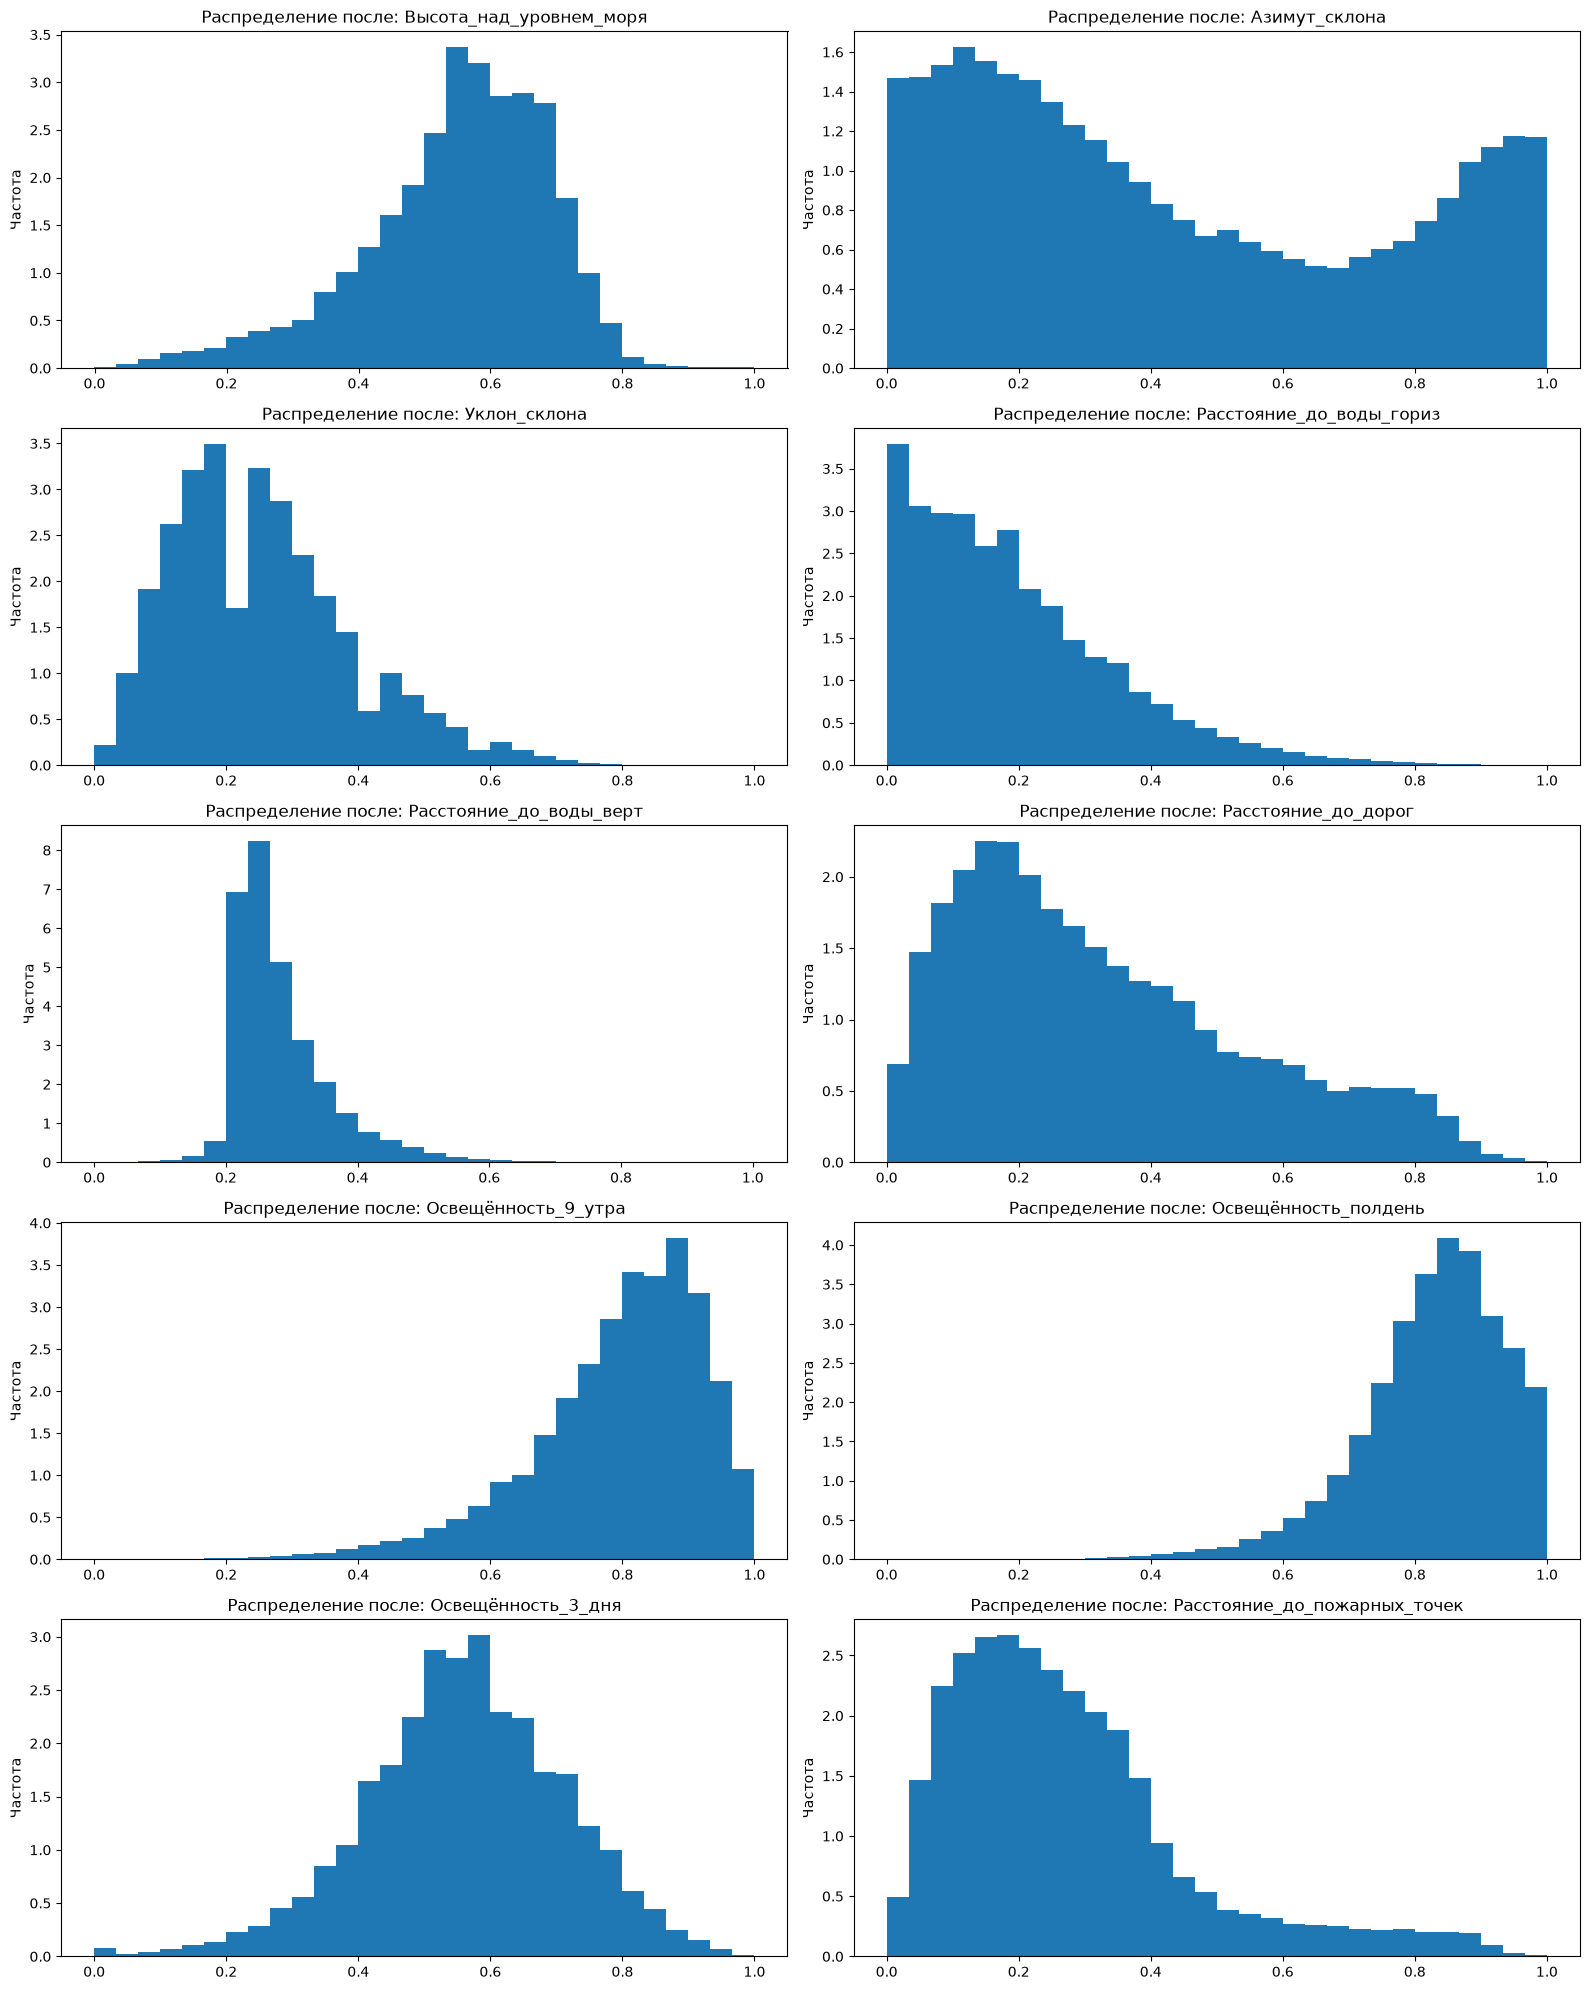

In [16]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(dfmm[col], bins=30, density=True)
    axes[i].set_title(f"Распределение после: {col}", fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Частота")

plt.tight_layout()
plt.show()

## Анализ

По статистическим данным после масштабирования можно сделать ряд выводов:

* После MinMax все признаки были приведены к унифицированному диапазону `[0; 1]`, в отличие от изначального датасета и стандартизации. Формально это уравнивает их статистически. Здесь же стоит заметить, что из за того, что параметры для масштабирования высчитывались только на тренировочной выборке, в тестовой есть некоторые артефакты, выходящие за границы заданного диапазона значений, однако это является вполне корректным поведением.
* Несмотря на примененный метод, хвосты в распределении все равно остаются, что отлично видно по медиане и стандартному отклонению.
* Межквартильный размах чисто визуально сильно сжался после применения MinMax.
* Форма распределения никак не изменилась, что видно по гистограммам

Из всего этого можно сделать вывод, что `MinMax` сильно сжимает центральную часть, оставляя хвосты. Это значит, что, даже если форма распредления осталась такой же, то центральная его часть стала более плотной.

Стоит упомянуть, что стандартизация привела все значения к стандартному отклонению равному 1.

Отметим, что для большиства задач стандратизация все же является более универсальной, так как не происходит ситуации, когда распредление сжимается в центре, не зависит от направления ассиметрии, а расстония и вклад признаков остаются на сопоставимом уровне. При этом, нормализация должна быть предпочтительнее, когда требуется привести данные, не имеющие экстремальных выбросов к конкретному диапазону.

In [17]:
print(dfs.dtypes)

Высота_над_уровнем_моря         float64
Азимут_склона                   float64
Уклон_склона                    float64
Расстояние_до_воды_гориз        float64
Расстояние_до_воды_верт         float64
Расстояние_до_дорог             float64
Освещённость_9_утра             float64
Освещённость_полдень            float64
Освещённость_3_дня              float64
Расстояние_до_пожарных_точек    float64
Зона_дикой_природы_1              int64
Зона_дикой_природы_2              int64
Зона_дикой_природы_3              int64
Зона_дикой_природы_4              int64
Тип_почвы_1                       int64
Тип_почвы_2                       int64
Тип_почвы_3                       int64
Тип_почвы_4                       int64
Тип_почвы_5                       int64
Тип_почвы_6                       int64
Тип_почвы_7                       int64
Тип_почвы_8                       int64
Тип_почвы_9                       int64
Тип_почвы_10                      int64
Тип_почвы_11                      int64


In [18]:
print('min & max')
for col in numeric_cols:
    print(f'{col}: min={dfs[col].min()}, max={dfs[col].max()}')

min & max
Высота_над_уровнем_моря: min=-3.9298747208454636, max=3.208445742806932
Азимут_склона: min=-1.3914280832950536, max=1.8235926096948654
Уклон_склона: min=-1.8855247924019163, max=5.470086709468595
Расстояние_до_воды_гориз: min=-1.2678951150958264, max=5.309212979723228
Расстояние_до_воды_верт: min=-3.7650733614478544, max=9.519010478839657
Расстояние_до_дорог: min=-1.507953992283802, max=3.0550287853437954
Освещённость_9_утра: min=-6.059382849538051, max=1.564929069316354
Освещённость_полдень: min=-7.4712977819218125, max=1.5548901752287858
Освещённость_3_дня: min=-3.7298209332393664, max=2.9147111692521417
Расстояние_до_пожарных_точек: min=-1.4957122969799679, max=3.922851986957162


In [20]:
print(f"Rows={dfs.shape[0]}", f"Columns={dfs.shape[1]}", sep='\t')
print(f'NaN: {dfs.isnull().sum().sum()}')

Rows=580966	Columns=55
NaN: 0


## Анализ

Итоговый датасет сохранил размерность на момент лаьораторной работы номер 5, но тип данных частично изменился. Применение стандартизации сильно сократило диапазоны значений числовых переменных, приведя их к сопоставимому формату. При этом категориальные не затрагивались, поэтому остались бинарными.

Технически, датасет после сэмплинга, будет готов к ML-задачам.

Риски, связанные с масштабированием во многом связаны с изначльным разбросом данных. Алгоритмы могут учитывать в большинстве признаки, имеющие наибольший диапазон значений, здесь же стоит упомянуть, что теоретически при обучении нейронной сети градиент на таких признаках будет убывать значительно сильнее, а на маленьких затухать, что может привести к нестабильности. Для регрессии такие значения в корне будут являться неверными, так как модель будет учитывать в большинстве только признаки с огоромными максимумами.

In [28]:
pd.concat([X_train, y_train], axis=1).to_csv('data/covtype-6-us.csv', index=False)
pd.concat([X_test, y_test], axis=1).to_csv('data/covtype-6-test-us.csv', index=False)

pd.concat([X_trs, y_train], axis=1).to_csv('data/covtype-6-s.csv', index=False)
pd.concat([X_tss, y_test], axis=1).to_csv('data/covtype-6-test-s.csv', index=False)

## Вывод. Связный текст

В лабораторной работе №5 был получен очищенный датасет Forest Cover Type размером 580 966 строк на 55 столбцов: без пропусков, без дубликатов и без очевидных выбросов. В текущей лабораторной работе была проведена работа по кодированию и масштабированию признаков. Категориальные признаки в этом случае также имели подобающий для дальнейшей работы закодированный вид OneHotEncoding.

Использованная последовтельность является верной. Пусть на момент начала работы используемый датасет уже был неплохо подготовлен, но, спускаясь в абстракцию можно понять некоторые закономерности. Допустим, масштабирование до очистки привело бы вероятно к тому, что экстремальные значения, сильно бы искозили парметры стандартизации, сжав значения в еще более узкий диапазон.

Ключевым является то, что перед началом работы было проведено разбиение выборки на тренировочную и тестовую; параметры маштабирования вычислялись только на тренировочной выборке, чтобы исключить утечку тестовых данных. Для масштабирования числовых переменных в моем случае был применен метод StandatdScaler, который привел все значения к сопоставимым диапазонам и стандартному отклонению равному единице. Сравнение с MinMax показало, что этот метод сильно сжимает центр распределения, поэтому хвосты начинают занимать большую часть диапазона. Для используемого датасета это может оказаться критично, так как распредление здесь далеко от нормального ввиду особенностей данных. Бинарные признаки не масштабировались и уже находились в надлежащем для работы виде.

Очищенная и подготовленная выборка готова к следующим работам. Она не содержит пропусков, категориальных значений за исключением целевой переменной, а все числовые признаки сопоставимы по масштабу. Итоговая размерность сохраняет изначальное распределение, обеспечивая достаточную статистическую мощность и будет полностью готова после отбора признаков и сэмплинга для уравнивания классов.